# Commuting in German cities: comparison

Reads the summary tables written by the per-city notebooks (`commuting_<city>.ipynb`, all with the same rule, months and thresholds)
and puts them side by side: panel sizes, how many residents get a work cell and why not, where residents work, and commute distances.
Run the city notebooks first; a city without results is skipped.

In [1]:
import os
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

PERIOD = "2024-05_2024-06"   # results of the two-month run of the city notebooks
COUNTRY = "DEU"
CITIES  = {"DEU": ["munich", "berlin", "hamburg", "frankfurt", "cologne"], "FRA": ["paris", "lyon", "marseille", "toulouse", "nice"]}[COUNTRY]
SCRATCH = Path(f"/scratch/project_2022768/{os.environ['USER']}/locomizer")
ACCENT = "#2A6DD9"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e5e7eb",
                     "grid.linewidth": 0.6, "axes.axisbelow": True, "figure.dpi": 110})

res = {}
for key in CITIES:
    d = SCRATCH / "results" / COUNTRY / f"{key}_{PERIOD}"
    if not (d / "counts.csv").exists():
        print("no results yet for", key); continue
    res[key] = {f.stem: pd.read_csv(f) for f in d.glob("*.csv")}
    res[key]["counts"] = pd.read_csv(d / "counts.csv", index_col=0).iloc[:, 0]
names = {key: res[key]["meta"].city.iloc[0] for key in res}
print("cities with results:", list(names.values()))

cities with results: ['Munich', 'Berlin', 'Hamburg', 'Frankfurt', 'Cologne']


## 1. Panel size per city

In [2]:
rows = []
for key, r in res.items():
    c, m = r["counts"], r["meta"].iloc[0]
    rows.append({"city": names[key], "FUA km²": m.fua_km2, "city km²": m.city_km2,
                 "FUA residents": c["FUA residents"], "with work cell": c["FUA residents with a work cell"],
                 "share with work cell": f"{100*c['FUA residents with a work cell']/c['FUA residents']:.0f}%",
                 "commuters (home or work in FUA)": c["commuters with home or work in the FUA"],
                 "city residents": c["city residents"], "workers in the city": c["workers in the city (any home)"]})
panel = pd.DataFrame(rows).set_index("city"); panel

,FUA km²,city km²,FUA residents,with work cell,share with work cell,commuters (home or work in FUA),city residents,workers in the city
city,,,,,,,,
Munich,5615,311,38488,21964,57%,24143,17850,11671
Berlin,9273,892,96220,59371,62%,61322,63009,40957
Hamburg,6135,743,53808,33271,62%,35599,28038,19757
Frankfurt,3395,248,45242,26339,58%,29647,10445,8311
Cologne,2479,407,37860,22244,59%,25350,15217,10272


## 2. Why residents have no work cell (share of FUA residents)

In [3]:
reasons = pd.concat([r["reasons"].assign(city=names[k]) for k, r in res.items()])
reasons["reason"] = reasons.reason.str[2:]
tab = reasons.pivot(index="reason", columns="city", values="pct_of_residents").fillna(0).round(1)
tab

city,Berlin,Cologne,Frankfurt,Hamburg,Munich
reason,,,,,
"away from home, but scattered over cells",23.0,24.1,22.8,22.9,24.7
daytime signals only at the home cell,14.9,16.7,18.5,14.8,17.6
has work cell in FUA,59.8,51.6,53.2,58.6,53.9
has work cell outside FUA,1.9,7.2,5.0,3.2,3.2
no 09-17 signals on enough working days,0.4,0.5,0.5,0.4,0.7
seen on too few working days,0.0,0.0,0.0,0.0,0.0


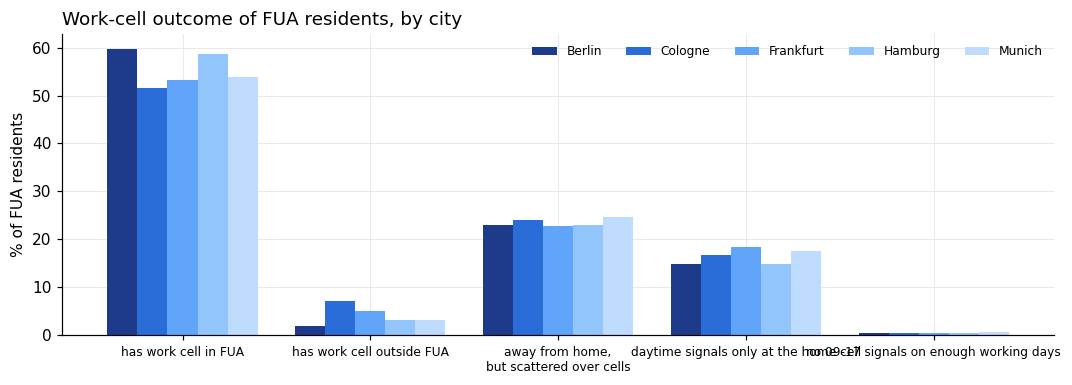

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.6))
order = ["has work cell in FUA", "has work cell outside FUA", "away from home, but scattered over cells", "daytime signals only at the home cell", "no 09-17 signals on enough working days"]
order = [o for o in order if o in tab.index]
x = np.arange(len(order)); w = 0.8 / max(len(tab.columns), 1)
shades = ["#1e3a8a", "#2A6DD9", "#60a5fa", "#93c5fd", "#bfdbfe"]
for i, city in enumerate(tab.columns):
    ax.bar(x + i * w - 0.4 + w / 2, tab.loc[order, city], width=w, color=shades[i % len(shades)], label=city)
ax.set_xticks(x); ax.set_xticklabels([o.replace(", ", ",\n") for o in order], fontsize=8)
ax.set_ylabel("% of FUA residents"); ax.set_title("Work-cell outcome of FUA residents, by city", loc="left"); ax.legend(frameon=False, ncol=5, fontsize=8)
plt.tight_layout(); plt.show()

## 3. Where do city residents work, and where do city workers live?

In [5]:
rows = []
for key, r in res.items():
    c = r["counts"]
    rows.append({"city": names[key],
                 "city residents with work cell": c["city residents with a work cell"],
                 "of which work inside the city": f"{100*c['  ... working inside the city']/c['city residents with a work cell']:.0f}%",
                 "workers in the city": c["workers in the city (any home)"],
                 "of which live inside the city": f"{100*c['  ... working inside the city']/c['workers in the city (any home)']:.0f}%"})
pd.DataFrame(rows).set_index("city")

,city residents with work cell,of which work inside the city,workers in the city,of which live inside the city
city,,,,
Munich,9761,81%,11671,68%
Berlin,37262,91%,40957,83%
Hamburg,16629,88%,19757,74%
Frankfurt,5671,79%,8311,54%
Cologne,8545,82%,10272,68%


## 4. Commute distance (km between home and work cell centres, home and work both in the metro)


In [6]:
dist = pd.concat([r["distance"].assign(city=names[k]) for k, r in res.items()])
pooled = dist[dist["group"] == "home and work in metro"].set_index("city")[["count", "25%", "50%", "75%"]]
missing = [c for c in names.values() if c not in pooled.index]
if missing: print("no pooled distance row yet, re-run the city notebook for:", missing)
pooled.reindex(names.values()).round(1)


,count,25%,50%,75%
city,,,,
Munich,20740.0,0.9,4.0,10.3
Berlin,57559.0,0.9,4.1,10.6
Hamburg,31552.0,0.9,4.0,10.4
Frankfurt,24063.0,0.9,3.2,8.9
Cologne,19531.0,0.9,3.0,7.5


## 5. Strongest district-to-district flows per city

In [7]:
pd.concat([r["district_flows"].head(5).assign(city=names[k]) for k, r in res.items()]).set_index(["city", "home_district", "work_district"])

users
city      home_district              work_district                   
Munich    München (Landkreis)        München (Stadt)             1127
          München (Stadt)            München (Landkreis)          935
          Fürstenfeldbruck           München (Stadt)              415
          Dachau                     München (Stadt)              394
          Ebersberg                  München (Stadt)              275
Berlin    Oberhavel                  Berlin                      1121
          Barnim                     Berlin                       985
          Märkisch-Oderland          Berlin                       880
          Dahme-Spreewald            Berlin                       855
          Teltow-Fläming             Berlin                       681
Hamburg   Pinneberg                  Hamburg                      970
          Harburg                    Hamburg                      843
          Stormarn                   Hamburg                      776
          Segeberg                   Hamburg                      688
          Herzogtum Lauenburg        Hamburg                      564
Frankfurt Offenbach (Landkreis)      Frankfurt am Main (Stadt)    503
          Main-Taunus-Kreis          Frankfurt am Main (Stadt)    458
          Main-Kinzig-Kreis          Frankfurt am Main (Stadt)    449
          Wetteraukreis              Frankfurt am Main (Stadt)    383
          Hochtaunuskreis            Frankfurt am Main (Stadt)    363
Cologne   Rhein-Erft-Kreis           Köln (Stadt)                 984
          Rhein-Sieg-Kreis           Köln (Stadt)                 503
          Köln (Stadt)               Rhein-Erft-Kreis             400
          Rheinisch-Bergischer Kreis Köln (Stadt)                 356
          Leverkusen (Stadt)         Köln (Stadt)                 256